In [1]:
import pandas as pd
import seaborn as sns

In [3]:
df= pd.read_csv("dds_datasets/dds_ch2_nyt/nyt1.csv")
df.shape

(458441, 5)

In [4]:
df.head()

,Age,Gender,Impressions,Clicks,Signed_In
0,36,0,3,0,1
1,73,1,3,0,1
2,30,0,3,0,1
3,49,1,3,0,1
4,47,1,11,0,1


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 458441 entries, 0 to 458440
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   Age          458441 non-null  int64
 1   Gender       458441 non-null  int64
 2   Impressions  458441 non-null  int64
 3   Clicks       458441 non-null  int64
 4   Signed_In    458441 non-null  int64
dtypes: int64(5)
memory usage: 17.5 MB


In [7]:
df.isnull().sum()

Age            0
Gender         0
Impressions    0
Clicks         0
Signed_In      0
dtype: int64

In [9]:
df.columns= [col.lower() for col in df]
df

,age,gender,impressions,clicks,signed_in
0,36,0,3,0,1
1,73,1,3,0,1
2,30,0,3,0,1
3,49,1,3,0,1
4,47,1,11,0,1
...,...,...,...,...,...
458436,0,0,2,0,0
458437,0,0,4,0,0
458438,72,1,5,0,1
458439,0,0,5,0,0


In [13]:
df.duplicated().sum()

np.int64(453503)

In [14]:
df.describe()

,age,gender,impressions,clicks,signed_in
count,458441.000000,458441.000000,458441.000000,458441.000000,458441.000000
mean,29.482551,0.367037,5.007316,0.092594,0.700930
std,23.607034,0.481997,2.239349,0.309973,0.457851
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,3.000000,0.000000,0.000000
50%,31.000000,0.000000,5.000000,0.000000,1.000000
75%,48.000000,1.000000,6.000000,0.000000,1.000000
max,108.000000,1.000000,20.000000,4.000000,1.000000


In [15]:
bins= [0,18,25,35,45,55,65,110]
labels = ['0<18','18-24','25-34','35-44','45-54','55-64','65+']
df['age_group']=pd.cut(df.age,bins,labels=labels, include_lowest=True)
df

,age,gender,impressions,clicks,signed_in,age_group
0,36,0,3,0,1,35-44
1,73,1,3,0,1,65+
2,30,0,3,0,1,25-34
3,49,1,3,0,1,45-54
4,47,1,11,0,1,45-54
...,...,...,...,...,...,...
458436,0,0,2,0,0,0<18
458437,0,0,4,0,0,0<18
458438,72,1,5,0,1,65+
458439,0,0,5,0,0,0<18


<Axes: xlabel='age_group', ylabel='count'>

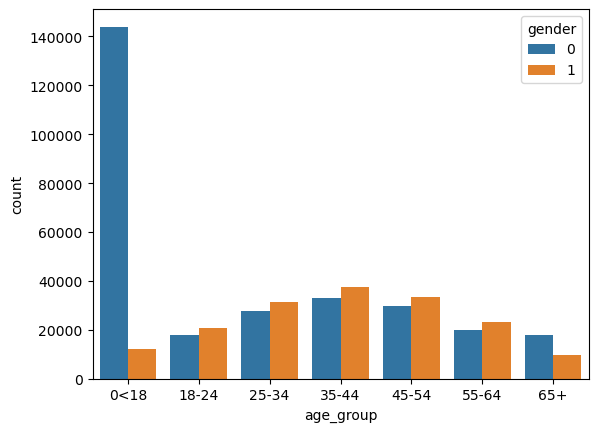

In [17]:
sns.countplot(x='age_group',hue='gender' ,data= df)

<Axes: xlabel='clicks', ylabel='count'>

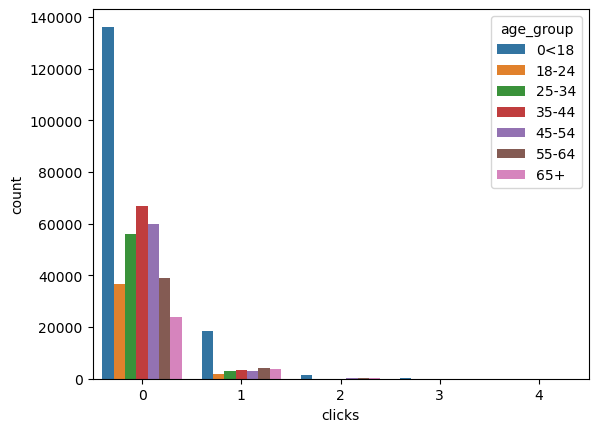

In [18]:
sns.countplot(x='clicks',hue='age_group',data= df)

In [20]:
df[(df['clicks']>0)&(df['impressions']==0)]

,age,gender,impressions,clicks,signed_in,age_group


<Axes: xlabel='impressions', ylabel='Count'>

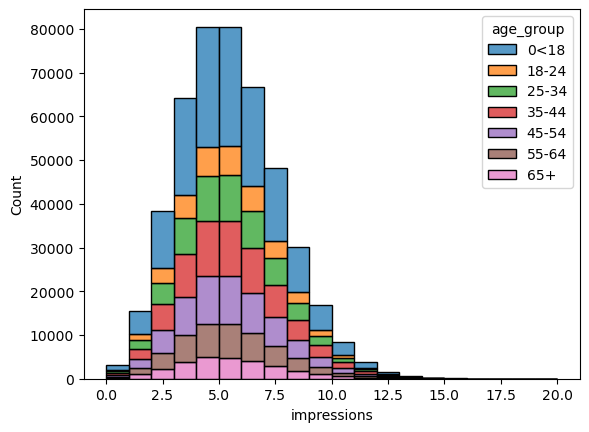

In [22]:
sns.histplot(df,x='impressions',hue='age_group',stat= 'count',binwidth=1,multiple='stack')

<Axes: xlabel='age_group', ylabel='impressions'>

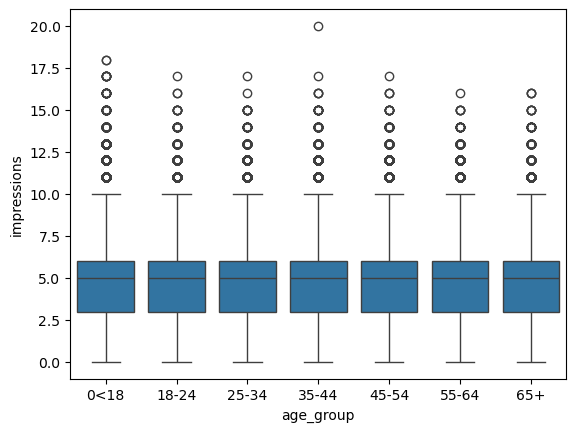

In [23]:
sns.boxplot(y=df['impressions'],x=df['age_group'])

In [25]:
df['CTR']=round(df['clicks']/df['impressions'],5)

<Axes: xlabel='age_group', ylabel='CTR'>

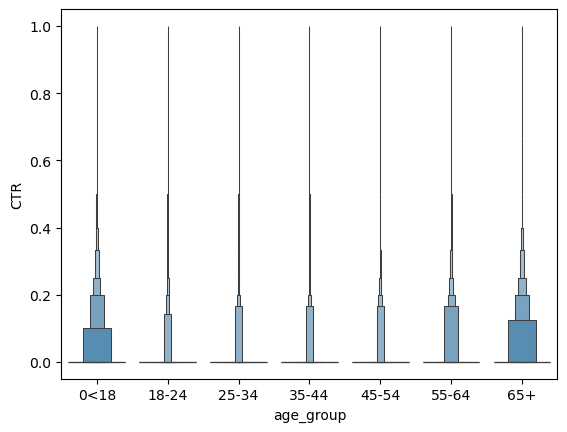

In [27]:
sns.boxenplot(x=df['age_group'],y =df['CTR'])